# Beamline Optimization - Initialization
This notebook performs sequential optimization of the UH beamline using custom modules and beam parameters.

Help for associated beamline element indexing: image.png

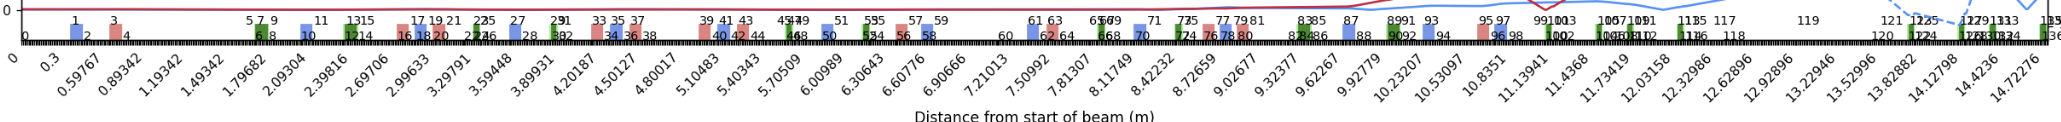

In [1]:
# Import Python modules
%matplotlib ipympl
import sys
import time
from pathlib import Path

# Locate the repository from the notebook's own folder (backend/test/)
REPO = Path.cwd().resolve()
while not (REPO / 'backend' / 'ebeam.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
if str(REPO / 'backend') not in sys.path:
    sys.path.insert(0, str(REPO / 'backend'))
import numpy as np
import pandas as pd
import sympy as sp
import sympy.plotting as plot

# Import Beam Dynamics modules
from ebeam import beam
from beamline import lattice, beamline
from schematic import draw_beamline
from excelElements import ExcelElements
from beamOptimizer import beamOptimizer
from AlgebraicOptimization import AlgebraicOpti

In [2]:
from parameters import chicane_inputs

# Initial Beam Parameters at the chicane entrance (parameters/UH_reference_parameters.yaml)
inputs = chicane_inputs()
Energy = inputs['kinetic_energy_eV'] * 1e-6  # MeV
f = 2856e6  # Hz
bunch_spread = inputs['sigma_t_s'] * 1e12  # ps
energy_std_percent = inputs['energy_spread_rms'] * 1e2  # %
h = 5e9  # 1/s

epsilon_n = inputs['emittance_n_x_m'] * 1e6  # pi.mm.mrad
nb_particles = 100000

relat = lattice(1,fringeType=None)
relat.setE(E=Energy)
norm = relat.gamma * relat.beta
epsilon = epsilon_n / norm
print(relat.gamma)
print(relat.beta)
print(epsilon)
x_std = np.sqrt(epsilon * inputs['beta_x_m'])  # mm, from mm.mrad * m at alpha = 0
y_std = np.sqrt(epsilon * inputs['beta_y_m'])  # mm
x_prime_std = epsilon / x_std
y_prime_std = epsilon / y_std

tof_std = bunch_spread * 1e-9 * f
gen_tof = np.random.normal(0, tof_std, size=(nb_particles, 1))
energy_std = energy_std_percent * 10

ebeam = beam()
beam_dist = ebeam.gen_6d_gaussian(0, [x_std,x_prime_std,y_std,y_prime_std,tof_std,energy_std], nb_particles)
tof_dist = beam_dist[:,4] / f
beam_dist[:,5] += h * tof_dist


# MkV FEL Undulator matching
K = 1.2
lambda_u = 2.3  # Undulator period in cm

beta_ym = relat.gamma / (K * (2 * np.pi / (lambda_u * 1e-2)))
print(beta_ym)
y_std_m = np.sqrt(epsilon * 1e-6 * beta_ym)
print(y_std_m)
y_prime_std_m = np.sqrt(epsilon * 1e-6 / beta_ym) # Beam at waist so Gamma(z_w) = 1 / Beta(z_w)
print(y_prime_std_m)

79.27804734236734
0.9999204424517368
0.100918687823807
0.24183528466987864
0.00015622323642269412
0.0006459902517366284


In [3]:
# Load Beamline from Excel
path = REPO / 'beam_excel'
file_path = path / 'Beamline_elements.xlsx'
excel = ExcelElements(file_path)
df = excel.get_dataframe()
beamlineUH = excel.create_beamline()
schem = draw_beamline()
line_UH = relat.changeBeamType("electron", Energy, beamlineUH)

# Optimizer and beamline truncation
print('Number of elements in beamline: ' + str(len(line_UH)))
segments = 138
line = line_UH[:segments]
opti = beamOptimizer(line, beam_dist)

Number of elements in beamline: 138


In [4]:
# Optimization - First Quadrupole Doublet

variables = {
    1: ["I", "current", lambda num:num],
    3: ["I2", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 1},
    "I2": {"bounds": (0, 10), "start": 1},
}

objectives = {8: [{"measure": ["x", "alpha"], "goal": 0, "weight":1},
                  {"measure": ["x", "beta"], "goal": 0.1, "weight":0.0}],
              9: [{"measure": ["y", "alpha"], "goal": 0, "weight":1},
                  {"measure": ["y", "beta"], "goal": 0.1, "weight":0.5}]}            

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

# old values
# line[1].current = 0.9989681933
# line[3].current = 1.044851479


x variables:
indice 1 new current value: 0.8399989076704515
indice 3 new current value: 1.0529742552034802

y objectives:
indice 8: x alpha value of -0.0005543653799262805
indice 8: x beta value of 0.9723959665911487
indice 9: y alpha value of -0.0005677488020533896
indice 9: y beta value of 0.1339896788017614
Final difference: 0.0001445696051150762

Total time: 1.201950750000833 s
Total iterations: 61



In [5]:
# Optimization - First Chromacity Quad

variables = {10: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {15: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


x variables:
indice 10 new current value: 3.9827148437500064

y objectives:
indice 15: x disper value of 1.1509946833039682e-07
Final difference: 1.324788760994002e-14

Total time: 0.6660510000001523 s
Total iterations: 40



In [6]:
# Optimization - Quadrupole Triplet

truncated_line = line[:17]
# Add half a quad
#truncated_line.append(qpfLattice(current = 3.816604, length=0.0889/2))

variables = {
    16: ["I", "current", lambda num:num],
    18: ["I2", "current", lambda num:num],
    20: ["I3", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 5},
    "I3": {"bounds": (0, 10), "start": 3},
}

objectives = {25: [{"measure": ["x", "alpha"], "goal": 0, "weight":1},
                  {"measure": ["x", "beta"], "goal": 0.1, "weight":0.5}],
              26: [{"measure": ["y", "alpha"], "goal": 0, "weight":1},
                  {"measure": ["y", "beta"], "goal": 0.1, "weight":0.5}]}     

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

# old values
# line[16].current = 2.4
# line[18].current = 5.108214683
# line[20].current = 3.142089844


x variables:
indice 16 new current value: 2.050882327084871
indice 18 new current value: 4.879391540769575
indice 20 new current value: 3.477287476299906

y objectives:
indice 25: x alpha value of 5.542216589271725e-05
indice 25: x beta value of 0.01319423173852535
indice 26: y alpha value of 0.00010674433148386453
indice 26: y beta value of 0.010312530712407975
Final difference: 0.0019473890603268944

Total time: 2.26742579099664 s
Total iterations: 115



In [7]:
# Optimization - Second Chromacity Quad

variables = {27: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {32: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


x variables:
indice 27 new current value: 4.687207031250008

y objectives:
indice 32: x disper value of 6.222844575875615e-07
Final difference: 3.8723794615504555e-13

Total time: 0.6059854160048417 s
Total iterations: 40



In [8]:
# Optimization - Double Quadrupole Triplet

variables = {
    37: ["I", "current", lambda num:num],
    35: ["I2", "current", lambda num:num],
    33: ["I3", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
    "I3": {"bounds": (0, 10), "start": 2},
}
objectives = {
    37: [
        {"measure": ["x", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["y", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["x", "envelope"], "goal": 2.0, "weight": 1},
        {"measure": ["y", "envelope"], "goal": 2.0, "weight": 1}
    ]
}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

line[43].current = line[33].current
line[41].current = line[35].current
line[39].current = line[37].current


x variables:
indice 37 new current value: 0.18576536971266616
indice 35 new current value: 2.538673449232528
indice 33 new current value: 2.643949832929133

y objectives:
indice 37: x alpha value of -0.007604150337340478
indice 37: y alpha value of -0.004465663900716789
indice 37: x envelope value of 1.416307897613793
indice 37: y envelope value of 1.6810093618562332
Final difference: 0.11063231571695624

Total time: 2.4218599579980946 s
Total iterations: 121



In [9]:
# Optimization - Third Chromacity Quad

variables = {50: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {55: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)



x variables:
indice 50 new current value: 4.682324218750008

y objectives:
indice 55: x disper value of -6.849438152926992e-07
Final difference: 4.691480301077193e-13

Total time: 0.6237481249991106 s
Total iterations: 40



In [10]:
# Optimization - Quadrupole Doublet and Interaction Point (z = 7.11 m, end of element index = 59)

variables = {
    56: ["I", "current", lambda num:num],
    58: ["I2", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
}

objectives = {
    59: [
        {"measure": ["x", "envelope"], "goal": 0.0, "weight": 1},
        {"measure": ["y", "envelope"], "goal": 0.0, "weight": 1}
    ]
}

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


x variables:
indice 56 new current value: 3.172482381026098
indice 58 new current value: 3.3228937852329072

y objectives:
indice 59: x envelope value of 0.021211240194419587
indice 59: y envelope value of 0.06421616829535194
Final difference: 0.0022868164905611625

Total time: 1.3076975000003586 s
Total iterations: 80



In [11]:
# Optimization - Quadrupole Doublet

variables = {
    61: ["I", "current", lambda num:num],
    63: ["I2", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
}

objectives = {
    68: [{"measure": ["x", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["x", "beta"], "goal": 0.1, "weight": 0.5}],
    69: [{"measure": ["y", "alpha"], "goal": 0, "weight": 1},
         {"measure": ["y", "beta"], "goal": 0.1, "weight": 0.5}]
}

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)



x variables:
indice 61 new current value: 5.166559928736185
indice 63 new current value: 4.010710952602167

y objectives:
indice 68: x alpha value of 0.00011426234649653628
indice 68: x beta value of 0.05672899376464954
indice 69: y alpha value of -0.00041363740420273076
indice 69: y beta value of 0.020336735869637565
Final difference: 0.0010273729920119493

Total time: 2.148026958995615 s
Total iterations: 114



In [12]:
# Optimization - Fourth Chromacity Quad

variables = {70: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {75: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


x variables:
indice 70 new current value: 4.6719726562500075

y objectives:
indice 75: x disper value of -4.1563801629356736e-08
Final difference: 1.7275496058845177e-15

Total time: 0.6048101670021424 s
Total iterations: 40



In [13]:
# Optimization - Quadrupole Triplet

variables = {
    76: ["I", "current", lambda num:num],
    78: ["I2", "current", lambda num:num],
    80: ["I3", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
    "I3": {"bounds": (0, 10), "start": 2},
}

objectives = {
    85: [{"measure": ["x", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["x", "beta"], "goal": 0.1, "weight": 0.5}],
    86: [{"measure": ["y", "alpha"], "goal": 0, "weight": 1},
         {"measure": ["y", "beta"], "goal": 0.1, "weight": 0.5}]
}

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


x variables:
indice 76 new current value: 3.858664330996719
indice 78 new current value: 4.056335113854391
indice 80 new current value: 0.04697975799438675

y objectives:
indice 85: x alpha value of 0.00018351179615356321
indice 85: x beta value of 0.07850216797604
indice 86: y alpha value of -0.0004043900769900533
indice 86: y beta value of 0.1279293935868511
Final difference: 0.0001553252779608788

Total time: 3.6476891250058543 s
Total iterations: 185



In [14]:
# Optimization - Fifth Chromacity Quad

variables = {87: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {92: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


x variables:
indice 87 new current value: 3.943457031250006

y objectives:
indice 92: x disper value of 1.4488406295034238e-07
Final difference: 2.0991391696998775e-14

Total time: 0.6457767080064514 s
Total iterations: 40



In [15]:
# Optimization - Quadrupole Triplet and MkIII undulator start (z = 12.389 m , end of element index = 117)

variables = {
    93: ["I", "current", lambda num:num],
    95: ["I2", "current", lambda num:num],
    97: ["I3", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
    "I3": {"bounds": (0, 10), "start": 2},
}
objectives = {
    117: [
        {"measure": ["x", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["y", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["x", "beta"], "goal": beta_ym, "weight": 1},
        {"measure": ["y", "beta"], "goal": beta_ym, "weight": 1}
    ]
}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


#indice 93 new current value: 2.1275944045328767
#indice 95 new current value: 1.543397467601471
#indice 97 new current value: 0.3798657737076452


x variables:
indice 93 new current value: 1.8742834278043508
indice 95 new current value: 1.428149215688685
indice 97 new current value: 2.515616197204183e-06

y objectives:
indice 117: x alpha value of -0.030019517926264918
indice 117: y alpha value of 0.07541504919271134
indice 117: x beta value of 0.27882698149936497
indice 117: y beta value of 1.0320091992056117
Final difference: 0.1580829504870783

Total time: 5.840799874997174 s
Total iterations: 307



Simulating Beamline:  98%|█████████▊| 1514/1550 [00:02<00:00]


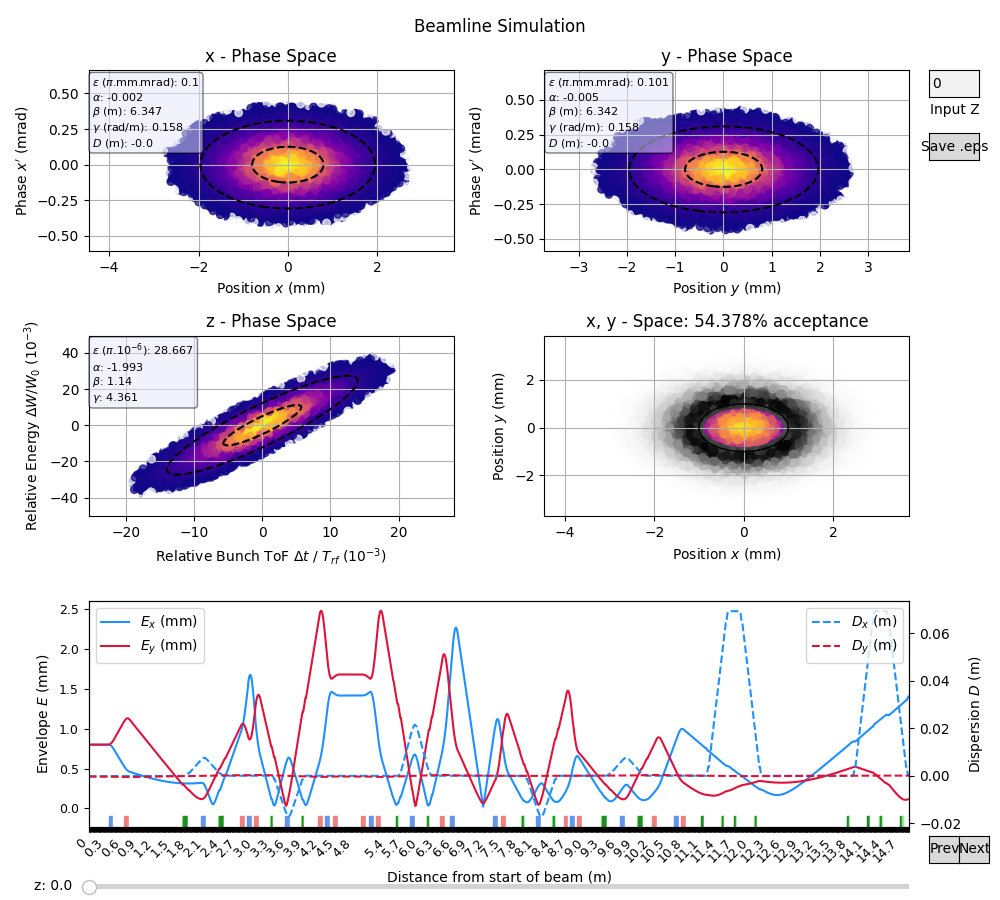

,$\epsilon$ ($\pi$.mm.mrad),$\alpha$,$\beta$ (m),$\gamma$ (rad/m),$D$ (m),$D^{\prime}$,$\phi$ (deg),Envelope $E$ (mm)
x,"[0.10037770516070411, 0.10037770516070414, 0.1...","[-0.0018979030866993372, -0.003473483396391711...","[6.346890703599697, 6.346944417464528, 6.34702...","[0.1575580309692375, 0.15755803096923746, 0.15...","[-0.00015087042116474714, -0.00015110540153425...","[-2.349803695041386e-05, -2.3498036950413907e-...","[-89.9824307677562, -89.96784562429579, -89.95...","[0.798176874967663, 0.7981802524540629, 0.7981..."
y,"[0.10097364144651254, 0.1009736414465126, 0.10...","[-0.00505564692342652, -0.006632528177833396, ...","[6.34179369417365, 6.341910575924666, 6.342058...","[0.1576881254406873, 0.15768812544068722, 0.15...","[-0.00038958541140012807, -0.00038982864483112...","[-2.4323343100241283e-05, -2.432334310024131e-...","[-89.95315943913441, -89.93855083766411, -89.9...","[0.8002212210403098, 0.8002285952021856, 0.800..."
z,"[28.66736822088027, 28.66736822087978, 28.6673...","[-1.9927491127978658, -1.9926838343746192, -1....","[1.1399890983355605, 1.1399294363346273, 1.139...","[4.360611021469113, 4.360611021469188, 4.36061...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[-25.52941864895312, -25.52870043297519, -25.5...","[5.716684987803228, 5.716535392807841, 5.71638..."


In [16]:
# Display Optimized Beamline

%matplotlib ipympl
acceptance = {"shape":'circle', "radius":1, "origin":[0,0]}
schem.plotBeamPositionTransform(beam_dist, line, 0.01, plot=True, showIndice=False, 
                                defineLim=False, matchScaling=False, shape=acceptance, scatter=True)

